In [1]:
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


def get_device() -> torch.device:
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


@dataclass
class SKNOConfig:
    input_dim: int          # flattened field dimension
    latent_dim: int = 64    # Koopman latent dimension
    hidden_dim: int = 128   # encoder/decoder hidden width
    l1_lambda: float = 1e-4
    koopman_weight: float = 1.0
    recon_weight: float = 1.0
    spectral_weight: float = 1e-4
    lr: float = 1e-3


class MLPEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, latent_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, latent_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class MLPDecoder(nn.Module):
    def __init__(self, latent_dim: int, hidden_dim: int, output_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.net(z)


class SparseKoopmanLayer(nn.Module):
    """
    Learnable sparse Koopman matrix.
    """
    def __init__(self, latent_dim: int):
        super().__init__()
        # Initialize near identity for stable short-horizon rollout
        K0 = torch.eye(latent_dim) + 0.01 * torch.randn(latent_dim, latent_dim)
        self.K = nn.Parameter(K0)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        # z: [batch, latent_dim]
        return z @ self.K.T

    @torch.no_grad()
    def soft_threshold(self, lam: float):
        """
        Proximal step for L1 sparsity.
        """
        self.K.data = torch.sign(self.K.data) * torch.clamp(
            torch.abs(self.K.data) - lam, min=0.0
        )


class SKNO(nn.Module):
    def __init__(self, cfg: SKNOConfig):
        super().__init__()
        self.cfg = cfg
        self.encoder = MLPEncoder(cfg.input_dim, cfg.hidden_dim, cfg.latent_dim)
        self.koopman = SparseKoopmanLayer(cfg.latent_dim)
        self.decoder = MLPDecoder(cfg.latent_dim, cfg.hidden_dim, cfg.input_dim)

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x)

    def evolve_latent(self, z: torch.Tensor) -> torch.Tensor:
        return self.koopman(z)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder(z)

    def forward(self, x_t: torch.Tensor):
        z_t = self.encode(x_t)
        z_next_pred = self.evolve_latent(z_t)
        x_next_pred = self.decode(z_next_pred)
        return x_next_pred, z_t, z_next_pred


def spectral_penalty(K: torch.Tensor) -> torch.Tensor:
    """
    Cheap stabilizer: penalize large operator norm surrogate.
    Uses Frobenius norm as a simple proxy.
    """
    return torch.norm(K, p="fro")


def loss_fn(
    model: SKNO,
    x_t: torch.Tensor,
    x_tp1: torch.Tensor,
    cfg: SKNOConfig,
):
    x_next_pred, z_t, z_next_pred = model(x_t)
    z_tp1_true = model.encode(x_tp1)

    pred_loss = F.mse_loss(x_next_pred, x_tp1)
    koopman_loss = F.mse_loss(z_next_pred, z_tp1_true)
    l1_loss = torch.sum(torch.abs(model.koopman.K))
    spec_loss = spectral_penalty(model.koopman.K)

    total = (
        cfg.recon_weight * pred_loss
        + cfg.koopman_weight * koopman_loss
        + cfg.l1_lambda * l1_loss
        + cfg.spectral_weight * spec_loss
    )

    metrics = {
        "total": total.item(),
        "pred": pred_loss.item(),
        "koopman": koopman_loss.item(),
        "l1": l1_loss.item(),
        "spec": spec_loss.item(),
    }
    return total, metrics


def train_step(
    model: SKNO,
    optimizer: torch.optim.Optimizer,
    x_t: torch.Tensor,
    x_tp1: torch.Tensor,
    cfg: SKNOConfig,
):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    total_loss, metrics = loss_fn(model, x_t, x_tp1, cfg)
    total_loss.backward()
    optimizer.step()

    # Proximal sparsification on Koopman matrix
    model.koopman.soft_threshold(cfg.lr * cfg.l1_lambda)
    return metrics


@torch.no_grad()
def rollout(model: SKNO, x0: torch.Tensor, steps: int) -> torch.Tensor:
    """
    Multi-step rollout from a single initial state.
    x0: [1, input_dim]
    Returns: [steps+1, input_dim]
    """
    model.eval()
    xs = [x0]
    x = x0
    for _ in range(steps):
        x, _, _ = model(x)
        xs.append(x)
    return torch.cat(xs, dim=0)


def make_toy_linear_field_data(
    n_samples: int,
    input_dim: int,
    noise_std: float = 0.01,
    device: torch.device = torch.device("cpu"),
):
    """
    Tiny synthetic dataset for smoke-testing the pipeline.
    """
    A = 0.98 * torch.eye(input_dim, device=device)
    A += 0.02 * torch.randn(input_dim, input_dim, device=device) / math.sqrt(input_dim)

    x_t = torch.randn(n_samples, input_dim, device=device)
    x_tp1 = x_t @ A.T + noise_std * torch.randn_like(x_t)
    return x_t, x_tp1


def main():
    device = get_device()
    print(f"Using device: {device}")

    cfg = SKNOConfig(
        input_dim=64,    # e.g. 8x8 field flattened
        latent_dim=32,
        hidden_dim=128,
        l1_lambda=1e-5,
        koopman_weight=1.0,
        recon_weight=1.0,
        spectral_weight=1e-6,
        lr=1e-3,
    )

    model = SKNO(cfg).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)

    x_t, x_tp1 = make_toy_linear_field_data(
        n_samples=512,
        input_dim=cfg.input_dim,
        device=device,
    )

    batch_size = 64
    n_epochs = 20

    for epoch in range(n_epochs):
        perm = torch.randperm(x_t.size(0), device=device)
        x_t_epoch = x_t[perm]
        x_tp1_epoch = x_tp1[perm]

        running = {"total": 0.0, "pred": 0.0, "koopman": 0.0}
        n_batches = 0

        for i in range(0, x_t.size(0), batch_size):
            xb = x_t_epoch[i:i + batch_size]
            yb = x_tp1_epoch[i:i + batch_size]
            metrics = train_step(model, optimizer, xb, yb, cfg)

            running["total"] += metrics["total"]
            running["pred"] += metrics["pred"]
            running["koopman"] += metrics["koopman"]
            n_batches += 1

        print(
            f"Epoch {epoch+1:02d} | "
            f"total={running['total']/n_batches:.6f} | "
            f"pred={running['pred']/n_batches:.6f} | "
            f"koopman={running['koopman']/n_batches:.6f}"
        )

    # Smoke test rollout
    x0 = x_t[:1]
    traj = rollout(model, x0, steps=5)
    print("Rollout shape:", traj.shape)
    print("Nonzero Koopman entries:",
          int((model.koopman.K.abs() > 1e-6).sum().item()))


if __name__ == "__main__":
    main()

Using device: mps
Epoch 01 | total=0.966942 | pred=0.966528 | koopman=0.000019
Epoch 02 | total=0.960622 | pred=0.960192 | koopman=0.000043
Epoch 03 | total=0.949048 | pred=0.948305 | koopman=0.000337
Epoch 04 | total=0.920277 | pred=0.917557 | koopman=0.002278
Epoch 05 | total=0.881718 | pred=0.875400 | koopman=0.005859
Epoch 06 | total=0.843147 | pred=0.837361 | koopman=0.005343
Epoch 07 | total=0.806497 | pred=0.801793 | koopman=0.004278
Epoch 08 | total=0.774046 | pred=0.770439 | koopman=0.003193
Epoch 09 | total=0.745340 | pred=0.742455 | koopman=0.002477
Epoch 10 | total=0.716879 | pred=0.714346 | koopman=0.002128
Epoch 11 | total=0.690901 | pred=0.688347 | koopman=0.002151
Epoch 12 | total=0.668513 | pred=0.666313 | koopman=0.001801
Epoch 13 | total=0.646443 | pred=0.644592 | koopman=0.001457
Epoch 14 | total=0.626978 | pred=0.625159 | koopman=0.001428
Epoch 15 | total=0.608253 | pred=0.606588 | koopman=0.001277
Epoch 16 | total=0.590567 | pred=0.588982 | koopman=0.001200
Epoch 

In [2]:
import matplotlib.pyplot as plt
import torch


def plot_loss_curves(history):
    plt.figure(figsize=(6, 4))
    plt.plot(history["total"], label="total")
    plt.plot(history["pred"], label="prediction")
    plt.plot(history["koopman"], label="koopman")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.title("Training Curves")
    plt.tight_layout()
    plt.show()


def plot_koopman_matrix(model):
    K = model.koopman.K.detach().cpu().numpy()
    plt.figure(figsize=(5, 4))
    plt.imshow(K, aspect="auto")
    plt.colorbar()
    plt.title("Learned Sparse Koopman Matrix")
    plt.tight_layout()
    plt.show()


def plot_field_prediction(x_true, x_pred, field_shape=(8, 8)):
    true_field = x_true.detach().cpu().reshape(field_shape).numpy()
    pred_field = x_pred.detach().cpu().reshape(field_shape).numpy()
    err_field = abs(true_field - pred_field)

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    axes[0].imshow(true_field)
    axes[0].set_title("Ground Truth")
    axes[1].imshow(pred_field)
    axes[1].set_title("Prediction")
    axes[2].imshow(err_field)
    axes[2].set_title("Absolute Error")

    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.show()


def plot_error_vs_width(widths, errors):
    plt.figure(figsize=(5, 4))
    plt.plot(widths, errors, marker="o")
    plt.xlabel("Latent / Channel Width")
    plt.ylabel("Prediction Error")
    plt.title("Error vs Channel Width")
    plt.tight_layout()
    plt.show()

In [4]:
device = get_device()

cfg = SKNOConfig(
    input_dim=64,
    latent_dim=32,
    hidden_dim=128
)

model = SKNO(cfg).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)

# create synthetic data
x_t, x_tp1 = make_toy_linear_field_data(
    n_samples=512,
    input_dim=cfg.input_dim,
    device=device
)

history = {"total": [], "pred": [], "koopman": []}

for epoch in range(20):

    metrics = train_step(model, optimizer, x_t, x_tp1, cfg)

    history["total"].append(metrics["total"])
    history["pred"].append(metrics["pred"])
    history["koopman"].append(metrics["koopman"])

print("training complete")

training complete


In [5]:
history = {"total": [], "pred": [], "koopman": []}

nonzero = (model.koopman.K.abs() > 1e-6).float().mean().item()

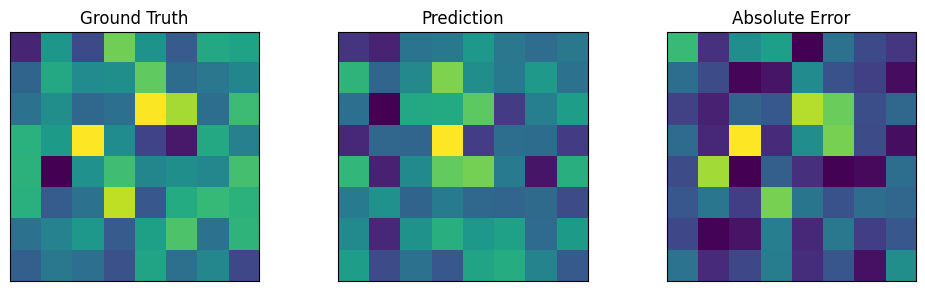

In [6]:
x0 = x_t[:1]
pred, _, _ = model(x0)

plot_field_prediction(x_tp1[0], pred[0])

In [7]:
K = model.koopman.K.detach()

sparsity = (K.abs() < 1e-5).float().mean()

print("sparsity ratio:", sparsity.item())

sparsity ratio: 0.00390625
